## Experiment 1: Data Loading, Storage and File Formats

**Aim:** To load and analyze sales data from multiple file formats (CSV, Excel and JSON), and perform data cleaning, transformation and analysis on the dataset.

In [1]:
# A52 Dipanshu Ambilkar
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
np.random.seed(1)
n = 120
df = pd.DataFrame({
    "OrderID": range(1, n + 1),
    "Product": np.random.choice(["Laptop", "Phone", "Tablet", "Headphones"], n),
    "Category": np.random.choice(["Electronics", "Accessories"], n),
    "Quantity": np.random.randint(1, 5, n),
    "Price": np.random.choice([999, 1499, 2499, 4999, 12999], n),
    "Region": np.random.choice(["North", "South", "East", "West"], n),
})
df.head()

,OrderID,Product,Category,Quantity,Price,Region
0,1,Phone,Electronics,2,1499,South
1,2,Headphones,Accessories,1,2499,South
2,3,Laptop,Accessories,2,1499,South
3,4,Laptop,Accessories,1,999,North
4,5,Headphones,Accessories,2,999,East


In [3]:
df.loc[np.random.choice(n, 8), "Price"] = np.nan
df = pd.concat([df, df.iloc[:5]], ignore_index=True)
print("shape after adding missing values and duplicates:", df.shape)

shape after adding missing values and duplicates: (125, 6)


In [4]:
df.to_csv("sales.csv", index=False)
df.to_excel("sales.xlsx", index=False)
df.to_json("sales.json", orient="records")
print("saved sales.csv, sales.xlsx, sales.json")

saved sales.csv, sales.xlsx, sales.json


In [5]:
c = pd.read_csv("sales.csv")
e = pd.read_excel("sales.xlsx")
j = pd.read_json("sales.json")
print("shapes:", c.shape, e.shape, j.shape)

shapes: (125, 6) (125, 6) (125, 6)


In [6]:
print("missing values in csv data:")
c.isnull().sum()

missing values in csv data:


OrderID     0
Product     0
Category    0
Quantity    0
Price       8
Region      0
dtype: int64

In [7]:
c = c.drop_duplicates()
c["Price"] = c["Price"].fillna(c["Price"].median())
print("rows in csv data now:", len(c))
print("missing prices now:", c["Price"].isnull().sum())

rows in csv data now: 120
missing prices now: 0


In [8]:
e = e.drop_duplicates()
e["Price"] = e["Price"].fillna(e["Price"].median())
print("rows in excel data now:", len(e))
print("missing prices now:", e["Price"].isnull().sum())

rows in excel data now: 120
missing prices now: 0


In [9]:
c["Total"] = c["Quantity"] * c["Price"]
c.head()

,OrderID,Product,Category,Quantity,Price,Region,Total
0,1,Phone,Electronics,2,1499.0,South,2998.0
1,2,Headphones,Accessories,1,2499.0,South,2499.0
2,3,Laptop,Accessories,2,1499.0,South,2998.0
3,4,Laptop,Accessories,1,999.0,North,999.0
4,5,Headphones,Accessories,2,999.0,East,1998.0


In [10]:
print(c.describe())

          OrderID    Quantity         Price         Total
count  120.000000  120.000000    120.000000    120.000000
mean    60.500000    2.500000   4778.166667  11180.833333
std     34.785054    1.173947   4610.362749  12336.461920
min      1.000000    1.000000    999.000000    999.000000
25%     30.750000    1.000000   1499.000000   2997.000000
50%     60.500000    3.000000   2499.000000   5996.000000
75%     90.250000    4.000000   4999.000000  12999.000000
max    120.000000    4.000000  12999.000000  51996.000000


In [11]:
print("Total sales:", c["Total"].sum())
print("Avg order value:", c["Total"].mean())

Total sales: 1341700.0
Avg order value: 11180.833333333334


In [12]:
c.groupby("Category")["Total"].sum()

Category
Accessories    693855.0
Electronics    647845.0
Name: Total, dtype: float64

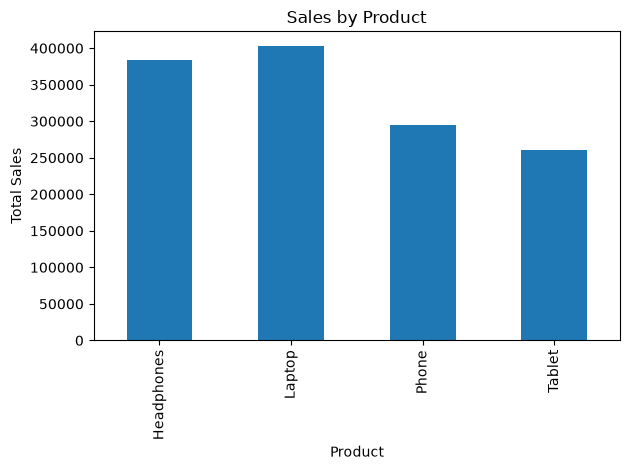

In [13]:
c.groupby("Product")["Total"].sum().plot(kind="bar")
plt.title("Sales by Product")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

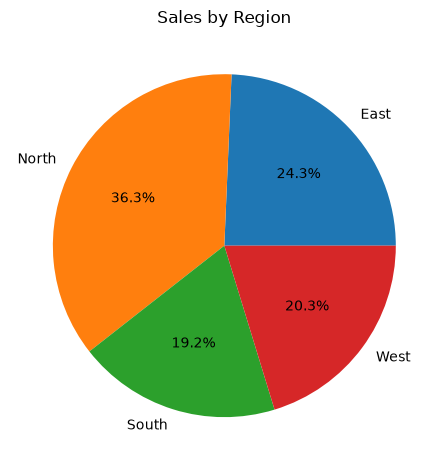

In [14]:
c.groupby("Region")["Total"].sum().plot(kind="pie", autopct="%1.1f%%")
plt.title("Sales by Region")
plt.ylabel("")
plt.tight_layout()
plt.show()

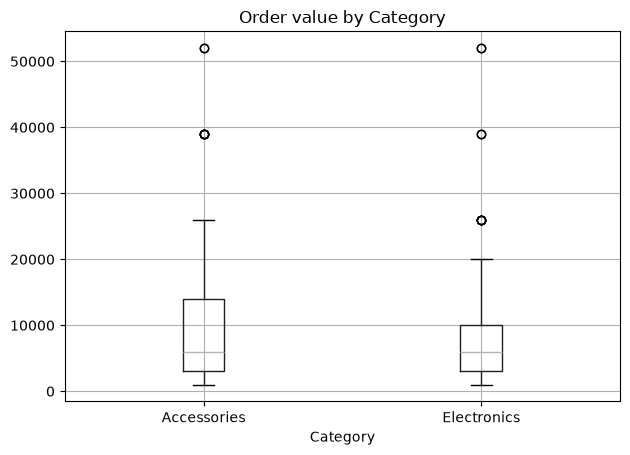

In [15]:
c.boxplot(column="Total", by="Category")
plt.title("Order value by Category")
plt.suptitle("")
plt.tight_layout()
plt.show()

In [16]:
print("done")

done
